In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Montando os arquivos finais (Juntando Partial do LLM-Judge e Meteor)

In [15]:
# Juntando as versões Partial do LLM-as-a-judge
modelos = ['DeepSeek', 'Gemma', 'Llama', 'Qwen']
for modelo in modelos:
    outros_modelos = [m for m in modelos if m != modelo]
    df1 = pd.read_csv(f'C:/PokeAI/databases/P&R/Metagame/3-LLM_Judge/Partial/LLM_Judge_{outros_modelos[0]}_{modelo}_Perguntas_Metagame.csv')
    df2 = pd.read_csv(f'C:/PokeAI/databases/P&R/Metagame/3-LLM_Judge/Partial/LLM_Judge_{outros_modelos[1]}_{modelo}_Perguntas_Metagame.csv')
    df3 = pd.read_csv(f'C:/PokeAI/databases/P&R/Metagame/3-LLM_Judge/Partial/LLM_Judge_{outros_modelos[2]}_{modelo}_Perguntas_Metagame.csv')

    colunas_comum = ['pergunta', 'resposta', 'contexto_RAG', 'resposta_gerada', 'bertscore_precision', 'bertscore_recall', 'bertscore_f1', 'moverscore', 'rougeL', 'rouge1', 'rouge2', 'bleu']
    # df_final será uma cópia do primeiro adicionado as colunas de avaliação dos outros dois
    df_final = df1.copy()

    colunas_novas = [col for col in df2.columns if col not in df_final.columns]
    df_final = pd.concat([df_final, df2[colunas_novas]], axis=1)

    colunas_novas = [col for col in df3.columns if col not in df_final.columns]
    df_final = pd.concat([df_final, df3[colunas_novas]], axis=1)

    # Adicionando a Meteor que foi calculada a parte
    df_meteor = pd.read_csv(f'C:/PokeAI/databases/P&R/Metagame/2-Automatic/Eval_Automatic_{modelo}_Perguntas_Metagame.csv')
    df_final['meteor'] = df_meteor['meteor']

    df_final.to_csv(f'C:/PokeAI/databases/P&R/Metagame/3-LLM_Judge/LLM_Judge_{modelo}_Perguntas_Metagame.csv', index=False)

# Avaliação de Média - LLM-as-a-judge, Semânticas e Geral (Não normalizada)

In [6]:
modelos = ['DeepSeek', 'Gemma', 'Llama', 'Qwen']

resultados = {}

for modelo in modelos:
    medias_LLM = []
    medias_sem = []
    medias_total = []
    print(f'Avaliação {modelo}:')
    df = pd.read_csv(f'C:/PokeAI/databases/P&R/Metagame/3-LLM_Judge/LLM_Judge_{modelo}_Perguntas_Metagame.csv')
    # Calculando a média das métricas de avaliação ('bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor', {criterio}_{outros_modelos})
    colunas_avaliar = [
        f'{criterio}_{juiz}'
        for juiz in [m for m in modelos if m != modelo]
        for criterio in ['fluencia', 'coerencia', 'coesao', 'completude', 'relevancia', 'factualidade', 'contextualizacao', 'utilidade', 'proposito']
    ]
    #colunas_avaliar += ['bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor']
    resultados[modelo] = []
    for col in colunas_avaliar:
        media = df[col].mean().round(2)
        medias_LLM.append(media)
        #print(f'    Média da coluna {col}: {media:.2f}')
        resultados[modelo].append({col:media})
    resultados[modelo].append({'LLM_as_a_judge':np.mean(medias_LLM).round(2)})
    print(f'    LLM_as_a_judge: {np.mean(medias_LLM):.2f} (Factualidade: {np.mean(medias_LLM[5]):.2f})')

    for col in ['bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor']:
        media = df[col].mean().round(2)
        medias_sem.append(media)
        #print(f'    Média da coluna {col}: {medias_sem:.2f}')
        resultados[modelo].append({col:media})
    print(f'    Semânticas: {np.mean(medias_sem):.2f}')

    for col in colunas_avaliar+['bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor']:
        media = df[col].mean()
        medias_total.append(media)
        #print(f'    Média da coluna {col}: {media:.2f}')
    print(f'    Geral (não normalizada): {np.mean(medias_total):.2f}')
    print("\n")   


Avaliação DeepSeek:
    LLM_as_a_judge: 2.82 (Factualidade: 2.39)
    Semânticas: 0.65
    Geral (não normalizada): 2.48


Avaliação Gemma:
    LLM_as_a_judge: 2.85 (Factualidade: 2.31)
    Semânticas: 0.76
    Geral (não normalizada): 2.52


Avaliação Llama:
    LLM_as_a_judge: 2.70 (Factualidade: 2.06)
    Semânticas: 0.81
    Geral (não normalizada): 2.40


Avaliação Qwen:
    LLM_as_a_judge: 2.56 (Factualidade: 1.93)
    Semânticas: 0.78
    Geral (não normalizada): 2.28




# Avaliação com Pesos Normalizada

In [7]:
df_resultados = pd.DataFrame({
    modelo: {
        list(item.keys())[0]: list(item.values())[0]
        for item in resultados[modelo]
    }
    for modelo in modelos
}).T

df_resultados.index.name = "Modelo"
df_resultados = df_resultados.reset_index()
df_resultados

,Modelo,fluencia_Gemma,coerencia_Gemma,coesao_Gemma,completude_Gemma,relevancia_Gemma,factualidade_Gemma,contextualizacao_Gemma,utilidade_Gemma,proposito_Gemma,...,meteor,fluencia_DeepSeek,coerencia_DeepSeek,coesao_DeepSeek,completude_DeepSeek,relevancia_DeepSeek,factualidade_DeepSeek,contextualizacao_DeepSeek,utilidade_DeepSeek,proposito_DeepSeek
0,DeepSeek,3.50,3.14,2.91,2.27,3.74,2.39,2.32,2.49,2.65,...,0.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gemma,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.14,2.99,2.65,2.92,2.50,2.91,2.31,2.68,2.63,2.64
2,Llama,3.73,3.08,3.01,2.81,4.08,2.96,2.81,3.08,3.28,...,0.15,3.12,2.72,2.86,2.29,2.86,2.06,2.47,2.41,2.40
3,Qwen,3.35,3.02,2.87,2.25,3.35,2.18,2.37,2.30,2.41,...,0.13,2.20,1.92,2.21,1.92,2.12,1.93,2.04,1.99,1.99


In [10]:
# Converter resultados em DataFrame
df_resultados = pd.DataFrame({
    modelo: {
        list(item.keys())[0]: list(item.values())[0]
        for item in resultados[modelo]
    }
    for modelo in modelos
}).T

df_resultados.index.name = "Modelo"
df_resultados = df_resultados.reset_index()

def normalizar(coluna):
    minimo = 1
    maximo = 5
    return (coluna - minimo) / (maximo - minimo)

# Adicionando a média de cada critério (sem diferenciar os juízes)
for criterio in ['fluencia', 'coerencia', 'coesao', 'completude', 'relevancia', 'factualidade', 'contextualizacao', 'utilidade', 'proposito']:
    colunas = [col for col in df_resultados.columns
        if col.startswith(f'{criterio}_')
    ]
    df_resultados[criterio] = normalizar(df_resultados[colunas].mean(axis=1))
    df_resultados[criterio+"_nao_norm"] = df_resultados[colunas].mean(axis=1)


pesos_criterios = {
    'fluencia': 2,
    'coerencia': 2,
    'coesao': 2,
    'completude': 2,
    'relevancia': 2,
    'factualidade': 3,
    'contextualizacao': 1,
    'utilidade': 2,
    'proposito': 2,
    'bertscore_f1': 1,
    'moverscore': 1,
    'rougeL': 1,
    'bleu': 1,
    'meteor': 1
}
# A coluna BLEU não foi convertida
df_resultados['bleu'] = df_resultados['bleu']/100

criterios = ['fluencia', 'coerencia', 'coesao', 'completude', 'relevancia', 'factualidade', 'contextualizacao', 'utilidade', 'proposito', 'bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor']
for index, row in df_resultados.iterrows():
    score = 0
    for criterio in criterios:
        score += row[criterio]*pesos_criterios[criterio]
    score = score/23
    print(f'Score do {row['Modelo']} = {score:.2f}')

Score do DeepSeek = 0.40
Score do Gemma = 0.41
Score do Llama = 0.39
Score do Qwen = 0.36


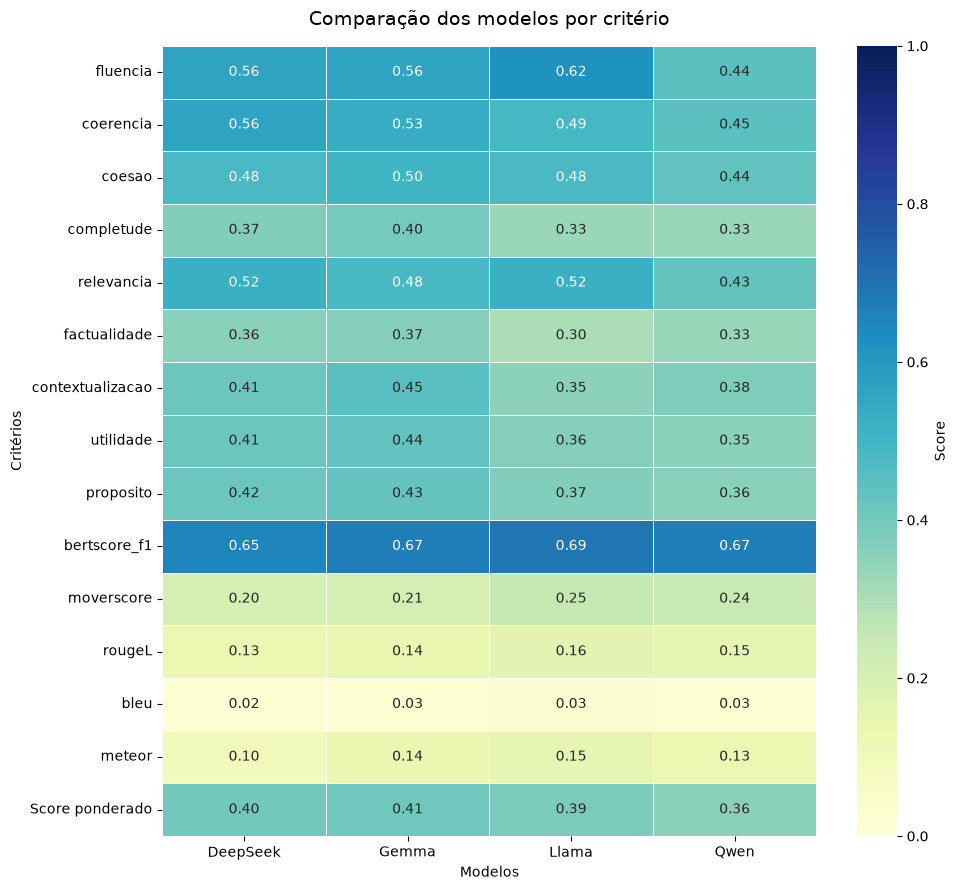

In [11]:
# Critérios
criterios = ['fluencia', 'coerencia', 'coesao', 'completude', 'relevancia', 'factualidade', 'contextualizacao', 'utilidade', 'proposito', 'bertscore_f1', 'moverscore', 'rougeL', 'bleu', 'meteor']

df_heatmap = df_resultados.set_index('Modelo')[criterios].T
scores = {}

for _, row in df_resultados.iterrows():
    score = sum(row[criterio] * pesos_criterios[criterio] for criterio in criterios) / 23
    scores[row['Modelo']] = score

# Adicionar score como última linha
df_heatmap.loc['Score ponderado'] = pd.Series(scores)

plt.figure(figsize=(10, 9))
sns.heatmap(df_heatmap, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, linewidths=0.5, cbar_kws={'label': 'Score'})
plt.title('Comparação dos modelos por critério', fontsize=14, pad=15)
plt.xlabel('Modelos')
plt.ylabel('Critérios')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
